In [ ]:
# Setup
from google.colab import drive
drive.mount('/content/drive')

!pip install -q transformers==4.40.0 accelerate sentencepiece

import os, numpy as np, pandas as pd, torch
import torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from scipy.stats import pearsonr

DEBERTA_CHECKPOINT = "microsoft/deberta-v3-base"
DEBERTA_WEIGHTS    = "/content/drive/Shareddrives/AI Capstone/Text model/deberta_model/best_model_v2.pt"
DATA_PATH          = "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/label_text_FULLY_PRUNED.csv"
SENTIMENT_NORM     = 3.0
MAX_LEN            = 128
BATCH_SIZE         = 16
EMOTION_COLS       = ["happy", "sad", "anger", "fear", "disgust", "surprise"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.6/137.6 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 114.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 49.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 96.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 5.4.1 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.40.0 which is incompatible.
Device: cuda


In [ ]:
import os, sys

!pip install -q timm==0.4.12 einops decord

# Audio (wav) flatten
WAV_FLAT = "/content/MOSEI_wav_flat"
if not os.path.exists(WAV_FLAT) or len(os.listdir(WAV_FLAT)) == 0:
    !unzip -q "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/Raw_Wav.zip" -d /content/MOSEI_wav
    !find /content/MOSEI_wav -name "._*" -delete
    !rm -rf /content/MOSEI_wav/__MACOSX
    import shutil
    SRC = "/content/MOSEI_wav/Raw_Wav"
    os.makedirs(WAV_FLAT, exist_ok=True)
    for vid in os.listdir(SRC):
        p = os.path.join(SRC, vid)
        if not os.path.isdir(p): continue
        for fname in os.listdir(p):
            if fname.endswith(".wav"):
                shutil.copy2(os.path.join(p, fname),
                              os.path.join(WAV_FLAT, f"{vid}__{fname.replace('.wav','')}.wav"))
    print(f"Flattened {len(os.listdir(WAV_FLAT))} wavs")
else:
    print(f"WAV flat dir present: {len(os.listdir(WAV_FLAT))} files")

# Video (mp4) flatten
MP4_FLAT = "/content/MOSEI_faces_flat"
if not os.path.exists(MP4_FLAT) or len(os.listdir(MP4_FLAT)) == 0:
    !unzip -q "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/Raw-Cropped-FULL.zip" -d /content/MOSEI_faces
    !find /content/MOSEI_faces -name "._*" -delete
    !rm -rf /content/MOSEI_faces/__MACOSX
    import shutil
    SRC = "/content/MOSEI_faces/Raw-Cropped-FULL"
    os.makedirs(MP4_FLAT, exist_ok=True)
    for vid in os.listdir(SRC):
        p = os.path.join(SRC, vid)
        if not os.path.isdir(p): continue
        for fname in os.listdir(p):
            if fname.endswith(".mp4"):
                shutil.copy2(os.path.join(p, fname),
                              os.path.join(MP4_FLAT, f"{vid}__{fname}"))
    print(f"Flattened {len(os.listdir(MP4_FLAT))} mp4s")
else:
    print(f"MP4 flat dir present: {len(os.listdir(MP4_FLAT))} files")

# MAE-DFER repo
if not os.path.exists("/content/MAE-DFER"):
    !git clone https://github.com/sunlicai/MAE-DFER.git /content/MAE-DFER

sys.path.insert(0, '/content/MAE-DFER')
import modeling_finetune
from timm.models import create_model

print("Setup cell done.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 377.0/377.0 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 88.9 MB/s eta 0:00:00
Flattened 22856 wavs
Flattened 22856 mp4s
Cloning into '/content/MAE-DFER'...
remote: Enumerating objects: 259, done.
remote: Counting objects: 100% (78/78), done.
remote: Compressing objects: 100% (61/61), done.
remote: Total 259 (delta 50), reused 17 (delta 17), pack-reused 181 (from 1)
Receiving objects: 100% (259/259), 16.52 MiB | 19.60 MiB/s, done.
Resolving deltas: 100% (98/98), done.
Setup cell done.


In [ ]:
# Imports + hyperparameters
import os, gc, random, shutil, copy, contextlib, collections
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import soundfile as sf
import cv2
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import (
    AutoModel, AutoTokenizer, AutoFeatureExtractor,
    HubertModel, get_cosine_schedule_with_warmup,
)
from sklearn.metrics import mean_absolute_error
from scipy.stats import pearsonr

# Paths
ENRICHED_CSV     = "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/label_FULLY_PRUNED.csv"
PREPROCESSED_CSV = "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/label_text_FULLY_PRUNED.csv"
FLAT_WAV_DIR     = "/content/MOSEI_wav_flat"
FLAT_MP4_DIR     = "/content/MOSEI_faces_flat"
OUTPUT_DIR       = "/content/drive/Shareddrives/AI Capstone/Middle Fusion/fusion-mosei-v61-clean"
os.makedirs(OUTPUT_DIR, exist_ok=True)

HUBERT_WEIGHTS   = "/content/drive/Shareddrives/AI Capstone/Audio Models/hubert-mosei-multitask-llrd/best_model.pt"
DEBERTA_WEIGHTS  = "/content/drive/Shareddrives/AI Capstone/Text model/deberta_model/best_model_v2.pt"
MAEDFER_WEIGHTS  = "/content/drive/Shareddrives/AI Capstone/Video Models/MAE-DFER/Checkpoints (Final Model)/best_model.pt"
MAEDFER_PRETRAIN = "/content/drive/Shareddrives/AI Capstone/Video Models/MAE-DFER/Pretrained/checkpoint-49.pth"

HUBERT_CHECKPOINT  = "facebook/hubert-base-ls960"
DEBERTA_CHECKPOINT = "microsoft/deberta-v3-base"

HUBERT_DIM  = 768
DEBERTA_DIM = 768
MAEDFER_DIM = 512

NUM_FRAMES    = 16
IMAGE_SIZE    = 160
VIDEO_MEAN    = [0.5, 0.5, 0.5]
VIDEO_STD     = [0.5, 0.5, 0.5]
SAMPLE_RATE   = 16_000
MAX_AUDIO_LEN = int(8.0 * SAMPLE_RATE)
MAX_TEXT_LEN  = 128

BATCH_SIZE       = 16
GRAD_ACCUM       = 2
MAX_EPOCHS       = 200
PATIENCE         = 15
LR_FUSION        = 5e-5
WD               = 0.01
WARMUP_RATIO     = 0.05
SEED             = 42
D_MODEL          = 256
NUM_HEADS        = 8
DROPOUT_PROB     = 0.35
CCC_ALPHA        = 0.6
LABEL_SMOOTHING  = 0.05
SENTIMENT_WEIGHT = 1.0
EMOTION_WEIGHT   = 1.0
POOL_LEN         = 16

# Mixture init logits [text, audio, video, fuse]
MIXTURE_INIT_SENT = [ 0.0, -1.3, -2.4, -0.8]
MIXTURE_INIT_EMOT = [-1.3,  0.0, -2.4, -0.8]

EMOTION_COLS      = ["happy", "sad", "anger", "fear", "disgust", "surprise"]
EMOTION_THRESHOLD = 0.5
V6_BEST_AVG_CCC   = 0.4307

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU  : {torch.cuda.get_device_name(0)}")
    print(f"VRAM : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
import transformers
print(f"transformers: {transformers.__version__}")

Device: cuda
GPU  : NVIDIA A100-SXM4-40GB
VRAM : 42.4 GB
transformers: 4.40.0


In [ ]:
# Metrics & losses
def ccc_np(y_true, y_pred):
    y_true = np.array(y_true, dtype=np.float64)
    y_pred = np.array(y_pred, dtype=np.float64)
    if np.std(y_true) < 1e-8 or np.std(y_pred) < 1e-8:
        return 0.0, 0.0
    rho, _    = pearsonr(y_true, y_pred)
    std_t, std_p = np.std(y_true), np.std(y_pred)
    mean_t, mean_p = np.mean(y_true), np.mean(y_pred)
    num = 2.0 * rho * std_t * std_p
    den = std_t**2 + std_p**2 + (mean_t - mean_p)**2
    return float(num / den if den > 1e-8 else 0.0), float(rho)


def ccc_loss_single(pred, target):
    mp, mt = pred.mean(), target.mean()
    cov    = ((pred - mp) * (target - mt)).mean()
    sp, st = pred.std(), target.std()
    if st < 1e-3 or sp < 1e-3:
        return torch.tensor(0.0, device=pred.device, requires_grad=True)
    den = sp**2 + st**2 + (mp - mt)**2 + 1e-4
    return 1.0 - (2.0 * cov) / den


def sentiment_loss(pred, target, alpha=CCC_ALPHA):
    return alpha * ccc_loss_single(pred, target) + (1.0 - alpha) * F.mse_loss(pred, target)


def emotion_loss(pred, target, emotion_weights, alpha=CCC_ALPHA, smoothing=LABEL_SMOOTHING):
    target_smooth = target * (1.0 - smoothing) + 0.5 * smoothing
    ccc = torch.stack([
        ccc_loss_single(pred[:, i], target[:, i]) * emotion_weights[i]
        for i in range(pred.shape[1])
    ]).mean()
    w   = emotion_weights.unsqueeze(0).expand_as(pred)
    bce = F.binary_cross_entropy(pred.clamp(1e-6, 1 - 1e-6),
                                  target_smooth.clamp(0, 1), weight=w)
    return alpha * ccc + (1.0 - alpha) * bce


In [ ]:
# Load labels + preprocessed-text merge
df = pd.read_csv(ENRICHED_CSV)
df["video_id"] = df["video_id"].astype(str)
df["clip_id"]  = df["clip_id"].astype(str)
df["wav_path"] = df.apply(lambda r: f"{FLAT_WAV_DIR}/{r['video_id']}__{r['clip_id']}.wav", axis=1)
df["mp4_path"] = df.apply(lambda r: f"{FLAT_MP4_DIR}/{r['video_id']}__{r['clip_id']}.mp4", axis=1)

before = len(df)
df = df[df["wav_path"].apply(os.path.exists) & df["mp4_path"].apply(os.path.exists)].copy()
print(f"Loaded {before} rows → kept {len(df)} with matching files")

df["sentiment_norm"] = df["sentiment"].clip(-3, 3) / 3.0
for col in EMOTION_COLS:
    df[col] = df[col].clip(0, 1)

# Match on label tuple + within-key position
df_uni = pd.read_csv(PREPROCESSED_CSV)
df_uni = df_uni.dropna(subset=['text'])
df_uni['text'] = df_uni['text'].astype(str).str.strip()
df_uni = df_uni[df_uni['text'] != ''].reset_index(drop=True)

key_cols = ['mode', 'sentiment', 'happy', 'sad', 'anger', 'fear', 'disgust', 'surprise']

df = df.reset_index(drop=True)
df['_pos_in_key']     = df.groupby(key_cols).cumcount()
df_uni['_pos_in_key'] = df_uni.groupby(key_cols).cumcount()

df_uni_subset = df_uni[key_cols + ['_pos_in_key', 'text']].rename(columns={'text': 'text_preprocessed'})

before = len(df)
df = df.merge(df_uni_subset, on=key_cols + ['_pos_in_key'], how='left').drop(columns=['_pos_in_key'])
after = len(df)
print(f"Merge: {before} → {after} rows (should be equal)")
print(f"Rows with preprocessed text: {df['text_preprocessed'].notna().sum()}")
print(f"Rows missing: {df['text_preprocessed'].isna().sum()}")

df = df[df['text_preprocessed'].notna()].reset_index(drop=True)

train_df = df[df["mode"] == "train"].reset_index(drop=True)
val_df   = df[df["mode"] == "valid"].reset_index(drop=True)
test_df  = df[df["mode"] == "test"].reset_index(drop=True)
print(f"After drop: Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}")

# Sanity-check alignment
print("\nVerifying test alignment after corrected join:")
for i in [0, 100, 1000, 2000, 3000, 4100]:
    if i < len(test_df):
        sent = test_df.iloc[i]['sentiment']
        orig = test_df.iloc[i]['text'][:50]
        prep = test_df.iloc[i]['text_preprocessed']
        print(f"  row {i}: sent={sent:.2f}")
        print(f"    orig: {orig}")
        print(f"    prep: {prep[:60]}")

EMOTION_WEIGHTS = torch.ones(6, dtype=torch.float32).to(device)
print("\nEmotion weights: uniform (all 1.0)")

Loaded 19970 rows → kept 19970 with matching files
Merge: 19970 → 19970 rows (should be equal)
Rows with preprocessed text: 15811
Rows missing: 4159
After drop: Train: 11096  Val: 1409  Test: 3306

Verifying test alignment after corrected join:
  row 0: sent=0.33
    orig: So the answer to the question, can I contribute st
    prep: answer question contribute stock ira absolutely correct alwa
  row 100: sent=0.33
    orig: And if you enjoyed the previous two DVDs, you have
    prep: enjoyed previous two dvds continue story
  row 1000: sent=1.33
    orig: And our sponsor, and having Cengage sponsor us has
    prep: sponsor cengage sponsor us helped
  row 2000: sent=0.33
    orig: -The report ranks major US retailers according to 
    prep: -the report ranks major us retailers according sustainable s
  row 3000: sent=0.33
    orig: We use open loop control, which allows quick imple
    prep: use open loop control allows quick implementation without us

Emotion weights: uniform (all 1.0)


In [ ]:
# Dataset & DataLoaders
audio_feature_extractor = AutoFeatureExtractor.from_pretrained(HUBERT_CHECKPOINT)
text_tokenizer          = AutoTokenizer.from_pretrained(DEBERTA_CHECKPOINT)
video_mean = np.array(VIDEO_MEAN, dtype=np.float32)
video_std  = np.array(VIDEO_STD,  dtype=np.float32)


def load_video_frames(mp4_path, num_frames=NUM_FRAMES, image_size=IMAGE_SIZE):
    cap   = cv2.VideoCapture(mp4_path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total < 1:
        cap.release()
        return torch.zeros(3, num_frames, image_size, image_size)
    indices = np.linspace(0, total - 1, num_frames, dtype=int)
    frames  = []
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ok, frame = cap.read()
        if ok:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame = cv2.resize(frame, (image_size, image_size))
        else:
            frame = np.zeros((image_size, image_size, 3), dtype=np.uint8)
        frame = ((frame.astype(np.float32) / 255.0) - video_mean) / video_std
        frames.append(frame)
    cap.release()
    return torch.from_numpy(np.stack(frames, axis=0)).permute(3, 0, 1, 2)


class MOSEIFusionDataset(Dataset):
    def __init__(self, df): self.df = df
    def __len__(self):       return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        try:   audio, _ = sf.read(row["wav_path"], dtype="float32")
        except: audio   = np.zeros(MAX_AUDIO_LEN, dtype=np.float32)
        if len(audio) > MAX_AUDIO_LEN:
            audio = audio[:MAX_AUDIO_LEN]
        text  = str(row["text_preprocessed"]) if pd.notna(row.get("text_preprocessed")) else str(row["text"])
        video = load_video_frames(row["mp4_path"])
        return (audio, text, video,
                float(row["sentiment_norm"]),
                [float(row[c]) for c in EMOTION_COLS])


def collate_fn(batch):
    audios, texts, videos, sentiments, emotions = zip(*batch)
    audio_inputs = audio_feature_extractor(
        list(audios), sampling_rate=SAMPLE_RATE, max_length=MAX_AUDIO_LEN,
        truncation=True, padding="max_length", return_tensors="pt")
    text_inputs = text_tokenizer(
        list(texts), padding="max_length", truncation=True,
        max_length=MAX_TEXT_LEN, return_tensors="pt")
    return {
        "input_values":     audio_inputs["input_values"],
        "input_ids":        text_inputs["input_ids"],
        "attention_mask":   text_inputs["attention_mask"],
        "pixel_values":     torch.stack(list(videos)),
        "sentiment_labels": torch.tensor(sentiments, dtype=torch.float32),
        "emotion_labels":   torch.tensor(emotions,   dtype=torch.float32),
    }


train_loader = DataLoader(MOSEIFusionDataset(train_df), batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=8, collate_fn=collate_fn, pin_memory=True)
val_loader   = DataLoader(MOSEIFusionDataset(val_df),   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=8, collate_fn=collate_fn, pin_memory=True)
test_loader  = DataLoader(MOSEIFusionDataset(test_df),  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=8, collate_fn=collate_fn, pin_memory=True)
print(f"Batches — train: {len(train_loader)}  val: {len(val_loader)}  test: {len(test_loader)}")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/213 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/transformers/convert_slow_tokenizer.py:560: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


Batches — train: 694  val: 89  test: 207


In [ ]:
# Load backbones (DeBERTa first!)
# DeBERTa FIRST
print("Loading DeBERTa first…")
deberta = AutoModel.from_pretrained(DEBERTA_CHECKPOINT)
state   = torch.load(DEBERTA_WEIGHTS, map_location=device, weights_only=False)
if "model_state_dict" in state: state = state["model_state_dict"]
deberta_state = {k[len("encoder."):]: v for k, v in state.items() if k.startswith("encoder.")}
m, u = deberta.load_state_dict(deberta_state, strict=False)
print(f"  DeBERTa load: {len(m)} missing, {len(u)} unexpected from {len(deberta_state)} keys")
for p in deberta.parameters(): p.requires_grad = False
deberta = deberta.to(device).eval()

# HuBERT
print("Loading HuBERT…")
hubert = HubertModel.from_pretrained(HUBERT_CHECKPOINT)
state  = torch.load(HUBERT_WEIGHTS, map_location=device, weights_only=False)
if "model_state_dict" in state: state = state["model_state_dict"]
hubert_state = {k[len("hubert."):]: v for k, v in state.items() if k.startswith("hubert.")}
m, u = hubert.load_state_dict(hubert_state, strict=False)
print(f"  HuBERT load: {len(m)} missing, {len(u)} unexpected")
for p in hubert.parameters(): p.requires_grad = False
hubert.feature_extractor._requires_grad = False
hubert.config.apply_spec_augment = False
hubert = hubert.to(device).eval()

# MAE-DFER
print("Loading MAE-DFER…")
class MAEDFERBackbone(nn.Module):
    def __init__(self, pretrain_ckpt):
        super().__init__()
        self.backbone = create_model(
            'vit_base_dim512_no_depth_patch16_160',
            pretrained=False, num_classes=7, all_frames=NUM_FRAMES,
            tubelet_size=2, use_mean_pooling=True,
            attn_type='local_global', lg_region_size=(2, 5, 10),
            lg_first_attn_type='self', lg_third_attn_type='cross',
            lg_attn_param_sharing_first_third=False, lg_attn_param_sharing_all=False,
            lg_classify_token_type='org', lg_no_second=False, lg_no_third=False,
            drop_path_rate=0.1, init_values=0.0,
        )
        self.backbone.head = nn.Identity()
        ckpt = torch.load(pretrain_ckpt, map_location='cpu', weights_only=False)
        self.backbone.load_state_dict(ckpt['model'] if 'model' in ckpt else ckpt, strict=False)
    def forward(self, x): return self.backbone(x)

maedfer  = MAEDFERBackbone(MAEDFER_PRETRAIN)
ft_state = torch.load(MAEDFER_WEIGHTS, map_location=device, weights_only=False)
if "model_state_dict" in ft_state: ft_state = ft_state["model_state_dict"]
maedfer.backbone.load_state_dict(
    {k.replace("backbone.", ""): v for k, v in ft_state.items() if not k.startswith("head.")},
    strict=False)
for p in maedfer.parameters(): p.requires_grad = False
maedfer = maedfer.to(device).eval()

if device.type == "cuda":
    print(f"VRAM after backbones: {torch.cuda.memory_allocated(device)/1e9:.2f} GB")


Loading DeBERTa first…


pytorch_model.bin:   0%|          | 0.00/371M [00:00<?, ?B/s]

  DeBERTa load: 0 missing, 0 unexpected from 198 keys
Loading HuBERT…


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/378M [00:00<?, ?B/s]

Some weights of the model checkpoint at facebook/hubert-base-ls960 were not used when initializing HubertModel: ['encoder.pos_conv_embed.conv.weight_g', 'encoder.pos_conv_embed.conv.weight_v']
- This IS expected if you are initializing HubertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing HubertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of HubertModel were not initialized from the model checkpoint at facebook/hubert-base-ls960 and are newly initialized: ['encoder.pos_conv_embed.conv.parametrizations.weight.original0', 'encoder.pos_conv_embed.conv.parametrizations.weight.original1']
You should probably TRAIN this model on a down-stream task to be able to use it for pre

  HuBERT load: 0 missing, 0 unexpected
Loading MAE-DFER…
==> Note: Use 'local_global' for compute reduction (lg_region_size=(2, 5, 10),lg_first_attn_type=self, lg_third_attn_type=cross,lg_attn_param_sharing_first_third=False,lg_attn_param_sharing_all=False,lg_classify_token_type=org,lg_no_second=False, lg_no_third=False)
==> Number of local regions: 8 (size=[4, 2, 1])
VRAM after backbones: 2.75 GB


In [ ]:
# Pure intermediate fusion (MulT-style cross-modal transformer)

class CrossModalLayer(nn.Module):
    def __init__(self, d_model, n_heads, ff_dim, dropout):
        super().__init__()
        self.norm_q  = nn.LayerNorm(d_model)
        self.norm_kv = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, n_heads, dropout=dropout, batch_first=True)
        self.norm_ff = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, ff_dim), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(ff_dim, d_model))
        self.drop = nn.Dropout(dropout)

    def forward(self, tgt, src, src_kpm=None):
        q  = self.norm_q(tgt)
        kv = self.norm_kv(src)
        a, _ = self.attn(q, kv, kv, key_padding_mask=src_kpm, need_weights=False)
        tgt = tgt + self.drop(a)
        tgt = tgt + self.drop(self.ff(self.norm_ff(tgt)))
        return tgt


class CrossModalStream(nn.Module):
    def __init__(self, d_model, n_heads, n_layers, ff_dim, dropout):
        super().__init__()
        self.layers = nn.ModuleList([
            CrossModalLayer(d_model, n_heads, ff_dim, dropout) for _ in range(n_layers)])
    def forward(self, tgt, src, src_kpm=None):
        for layer in self.layers:
            tgt = layer(tgt, src, src_kpm=src_kpm)
        return tgt


class IntermediateFusionModel(nn.Module):
    N_CROSS_LAYERS = 4
    N_SELF_LAYERS  = 2
    FF_DIM         = 1024
    MOD_DROPOUT_P  = 0.15

    def __init__(self, d_model=D_MODEL, n_heads=NUM_HEADS, dropout=DROPOUT_PROB):
        super().__init__()
        # Input projections
        self.proj_t = nn.Linear(DEBERTA_DIM, d_model)
        self.proj_a = nn.Linear(HUBERT_DIM,  d_model)
        self.proj_v = nn.Linear(MAEDFER_DIM, d_model)
        self.norm_t = nn.LayerNorm(d_model)
        self.norm_a = nn.LayerNorm(d_model)
        self.norm_v = nn.LayerNorm(d_model)

        # 6 cross-modal streams (each modality attends to each other)
        mk = lambda: CrossModalStream(d_model, n_heads, self.N_CROSS_LAYERS, self.FF_DIM, dropout)
        self.t_from_a, self.t_from_v = mk(), mk()
        self.a_from_t, self.a_from_v = mk(), mk()
        self.v_from_t, self.v_from_a = mk(), mk()

        # Self-attention over concatenated cross outputs per modality (dim = 2*d_model)
        def self_enc(d):
            layer = nn.TransformerEncoderLayer(
                d_model=d, nhead=n_heads, dim_feedforward=self.FF_DIM,
                dropout=dropout, activation='gelu', batch_first=True, norm_first=True)
            return nn.TransformerEncoder(layer, self.N_SELF_LAYERS)
        self.self_t = self_enc(d_model * 2)
        self.self_a = self_enc(d_model * 2)
        self.self_v = self_enc(d_model * 2)

        fusion_dim = d_model * 2 * 3
        self.fusion_norm = nn.LayerNorm(fusion_dim)
        self.fusion_drop = nn.Dropout(dropout)

        # Heads
        self.sent_head = nn.Sequential(
            nn.Linear(fusion_dim, d_model), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(d_model, 1), nn.Tanh())
        self.emot_head = nn.Sequential(
            nn.Linear(fusion_dim, d_model), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(d_model, 6), nn.Sigmoid())

    @staticmethod
    def _masked_mean(x, kpm):
        if kpm is None: return x.mean(dim=1)
        keep = (~kpm).float().unsqueeze(-1)
        s = (x * keep).sum(dim=1)
        n = keep.sum(dim=1).clamp(min=1.0)
        return s / n

    def _sample_mod_dropout(self, B, device):
        keep = (torch.rand(B, 3, device=device) > self.MOD_DROPOUT_P).float()
        all_zero = (keep.sum(dim=1) == 0)
        if all_zero.any():
            idx = torch.randint(0, 3, (all_zero.sum().item(),), device=device)
            keep[all_zero, idx] = 1.0
        return keep

    def forward(self, text_feat, video_feat, audio_feat, text_mask=None,
                sentiment_labels=None, emotion_labels=None, emotion_weights=None):
        # Video is pooled (B, 512) → make it a 1-token sequence
        if video_feat.dim() == 2:
            video_feat = video_feat.unsqueeze(1)

        # Padding key-mask for text (True = pad)
        t_kpm = (text_mask == 0) if text_mask is not None else None

        # Project + norm
        t = self.norm_t(self.proj_t(text_feat))
        a = self.norm_a(self.proj_a(audio_feat))
        v = self.norm_v(self.proj_v(video_feat))

        # Six cross-modal streams
        t_a = self.t_from_a(t, a)
        t_v = self.t_from_v(t, v)
        a_t = self.a_from_t(a, t, src_kpm=t_kpm)
        a_v = self.a_from_v(a, v)
        v_t = self.v_from_t(v, t, src_kpm=t_kpm)
        v_a = self.v_from_a(v, a)

        # Self-attention over concatenated streams per modality
        t_self = self.self_t(torch.cat([t_a, t_v], dim=-1), src_key_padding_mask=t_kpm)
        a_self = self.self_a(torch.cat([a_t, a_v], dim=-1))
        v_self = self.self_v(torch.cat([v_t, v_a], dim=-1))

        # Pool (mean) per modality
        t_pool = self._masked_mean(t_self, t_kpm)
        a_pool = a_self.mean(dim=1)
        v_pool = v_self.mean(dim=1)

        # Modality dropout (training only)
        if self.training:
            keep = self._sample_mod_dropout(t_pool.size(0), t_pool.device)
            scale = 3.0 / keep.sum(dim=1, keepdim=True).clamp(min=1.0)
            t_pool = t_pool * keep[:, 0:1] * scale
            a_pool = a_pool * keep[:, 1:2] * scale
            v_pool = v_pool * keep[:, 2:3] * scale

        fused = self.fusion_drop(self.fusion_norm(
            torch.cat([t_pool, a_pool, v_pool], dim=-1)))

        sent_pred = self.sent_head(fused).squeeze(-1)
        emot_pred = self.emot_head(fused)

        loss = None
        if sentiment_labels is not None and emotion_labels is not None:
            ew = emotion_weights if emotion_weights is not None \
                 else torch.ones(6, device=emot_pred.device)
            loss = (SENTIMENT_WEIGHT * sentiment_loss(sent_pred, sentiment_labels) +
                    EMOTION_WEIGHT   * emotion_loss(emot_pred, emotion_labels, ew))

        # Return tuple matching v6.1b's signature so eval/training cells work
        aux = {
            'sent_text': sent_pred, 'sent_audio': sent_pred, 'sent_video': sent_pred, 'sent_fuse': sent_pred,
            'emot_text': emot_pred, 'emot_audio': emot_pred, 'emot_video': emot_pred, 'emot_fuse': emot_pred,
            'w_sent': torch.zeros(4, device=sent_pred.device),
            'w_emot': torch.zeros(4, device=sent_pred.device),
        }
        return loss, sent_pred, emot_pred, aux


fusion = IntermediateFusionModel().to(device)
n_p = sum(p.numel() for p in fusion.parameters() if p.requires_grad)
print(f'Intermediate fusion trainable params: {n_p/1e6:.2f}M')

Intermediate fusion trainable params: 32.90M


/tmp/ipykernel_600/2290437128.py:64: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  return nn.TransformerEncoder(layer, self.N_SELF_LAYERS)


In [ ]:
# Optimizer
RESUME_CKPT = f"{OUTPUT_DIR}/resume_checkpoint_intermediate.pt"

optimizer = AdamW(fusion.parameters(), lr=LR_FUSION, weight_decay=WD, betas=(0.9, 0.98))
total_steps = (len(train_loader) // GRAD_ACCUM) * MAX_EPOCHS
scheduler   = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * WARMUP_RATIO),
    num_training_steps=total_steps)

history = {
    "train_loss": [], "val_loss": [],
    "sent_ccc": [], "sent_plcc": [], "sent_mae": [],
    "mean_emot_ccc": [], "emot_mae": [],
}

best_avg_ccc      = -1.0
best_epoch        = 0
patience_count    = 0
start_epoch       = 1
best_fusion_state = copy.deepcopy(fusion.state_dict())

if os.path.exists(RESUME_CKPT):
    try:
        print("Checkpoint found — resuming…")
        ckpt = torch.load(RESUME_CKPT, map_location=device, weights_only=False)
        fusion.load_state_dict(ckpt["model_state_dict"])
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        scheduler.load_state_dict(ckpt["scheduler_state_dict"])
        best_avg_ccc      = ckpt["best_avg_ccc"]
        best_epoch        = ckpt["best_epoch"]
        patience_count    = ckpt["patience_count"]
        history           = ckpt["history"]
        best_fusion_state = ckpt["best_model_state_dict"]
        start_epoch       = ckpt["epoch"] + 1
        print(f"  Resumed from epoch {ckpt['epoch']}  best avg CCC: {best_avg_ccc:.4f}")
    except (RuntimeError, KeyError) as e:
        print(f"  ⚠ Checkpoint corrupt ({e}) — starting fresh")
        os.remove(RESUME_CKPT)
else:
    print("No checkpoint — fresh start")
print(f"Start epoch: {start_epoch}  best avg CCC so far: {best_avg_ccc:.4f}")

Checkpoint found — resuming…
  Resumed from epoch 8  best avg CCC: 0.4744
Start epoch: 9  best avg CCC so far: 0.4744


In [ ]:
# Feature extraction with hook for video sequence
# Hook MAE-DFER's last block to capture pre-pool tokens
_cap = {}
def _video_hook(mod, inp, out): _cap['raw'] = out.detach()
_hook = maedfer.backbone.blocks[-1].register_forward_hook(_video_hook)

def extract_features(batch):
    with torch.no_grad():
        audio_feat = hubert(input_values=batch["input_values"].to(device)).last_hidden_state.float()
        text_feat  = deberta(input_ids=batch["input_ids"].to(device),
                              attention_mask=batch["attention_mask"].to(device)).last_hidden_state.float()
        _ = maedfer(batch["pixel_values"].to(device))
        # Use raw last-block tokens as video sequence
        raw = _cap['raw']  # (B*N, S+1, 512)
        if raw.shape[0] == batch["pixel_values"].size(0):
            video_seq = raw
        else:
            B = batch["pixel_values"].size(0)
            N = raw.shape[0] // B
            local = raw[:, 1:, :]
            video_seq = local.reshape(B, N * local.shape[1], -1)
    return text_feat, video_seq, audio_feat

In [ ]:
# Evaluate (no aux heads)
def evaluate(loader):
    fusion.eval()
    all_sp, all_st, all_ep, all_et = [], [], [], []
    total_loss = 0.0

    with torch.no_grad():
        for batch in loader:
            tf, vf, af = extract_features(batch)
            tmask = batch["attention_mask"].to(device)
            slbl  = batch["sentiment_labels"].to(device)
            elbl  = batch["emotion_labels"].to(device)

            loss, sp, ep, _ = fusion(
                tf, vf, af, text_mask=tmask,
                sentiment_labels=slbl, emotion_labels=elbl,
                emotion_weights=EMOTION_WEIGHTS)
            total_loss += loss.item()

            all_sp.extend((sp.cpu().numpy() * 3).tolist())
            all_st.extend((slbl.cpu().numpy() * 3).tolist())
            all_ep.extend(ep.cpu().numpy().tolist())
            all_et.extend(elbl.cpu().numpy().tolist())

    all_ep = np.array(all_ep); all_et = np.array(all_et)
    sent_ccc, sent_plcc = ccc_np(all_st, all_sp)
    emot_ccc_scores     = [ccc_np(all_et[:, i], all_ep[:, i])[0] for i in range(6)]

    return {
        "loss": total_loss / len(loader),
        "sent_ccc": sent_ccc, "sent_plcc": sent_plcc,
        "sent_mae": mean_absolute_error(all_st, all_sp),
        "emot_ccc_scores": emot_ccc_scores,
        "mean_emot_ccc":   float(np.mean(emot_ccc_scores)),
        "emot_mae": mean_absolute_error(all_et.flatten(), all_ep.flatten()),
        "sent_pred": all_sp, "sent_true": all_st,
        "emot_pred": all_ep, "emot_true": all_et,
    }

In [ ]:
# Sanity check (no aux heads)
gc.collect(); torch.cuda.empty_cache()
batch = next(iter(train_loader))
tf, vf, af = extract_features(batch)
tmask = batch["attention_mask"].to(device)
slbl  = batch["sentiment_labels"].to(device)
elbl  = batch["emotion_labels"].to(device)

print(f"Feature shapes: text={tf.shape}  video={vf.shape}  audio={af.shape}")
fusion.train()
loss, sp, ep, _ = fusion(tf, vf, af, text_mask=tmask,
                          sentiment_labels=slbl, emotion_labels=elbl,
                          emotion_weights=EMOTION_WEIGHTS)
print(f"Fusion: loss={loss.item():.4f}  "
      f"sent=[{sp.min():.2f},{sp.max():.2f}]  emot_mean={ep.mean():.3f}")
(loss / GRAD_ACCUM).backward()
optimizer.zero_grad()
print(f"✓ Sanity passed  |  VRAM: {torch.cuda.memory_allocated()/1e9:.2f} GB")
gc.collect(); torch.cuda.empty_cache()

Feature shapes: text=torch.Size([16, 128, 768])  video=torch.Size([16, 800, 512])  audio=torch.Size([16, 399, 768])
Fusion: loss=1.6967  sent=[-0.36,0.17]  emot_mean=0.507
✓ Sanity passed  |  VRAM: 3.15 GB


In [ ]:
# Training loop with tqdm bars
from tqdm.auto import tqdm

print(f"\n{'Ep':>3} {'TrLoss':>8} {'VlLoss':>8} {'SCCC':>8} {'SPLCC':>8} {'SMAE':>8} {'ECCC':>8} {'P':>4}")
print("─" * 64)

def evaluate_with_bar(loader, desc='val'):
    fusion.eval()
    all_sp, all_st, all_ep, all_et = [], [], [], []
    total_loss = 0.0
    with torch.no_grad():
        for batch in tqdm(loader, desc=desc, leave=False):
            tf, vf, af = extract_features(batch)
            tmask = batch["attention_mask"].to(device)
            slbl  = batch["sentiment_labels"].to(device)
            elbl  = batch["emotion_labels"].to(device)
            loss, sp, ep, _ = fusion(tf, vf, af, text_mask=tmask,
                                      sentiment_labels=slbl, emotion_labels=elbl,
                                      emotion_weights=EMOTION_WEIGHTS)
            total_loss += loss.item()
            all_sp.extend((sp.cpu().numpy() * 3).tolist())
            all_st.extend((slbl.cpu().numpy() * 3).tolist())
            all_ep.extend(ep.cpu().numpy().tolist())
            all_et.extend(elbl.cpu().numpy().tolist())
    all_ep = np.array(all_ep); all_et = np.array(all_et)
    sent_ccc, sent_plcc = ccc_np(all_st, all_sp)
    emot_ccc_scores     = [ccc_np(all_et[:, i], all_ep[:, i])[0] for i in range(6)]
    return {
        "loss": total_loss / len(loader),
        "sent_ccc": sent_ccc, "sent_plcc": sent_plcc,
        "sent_mae": mean_absolute_error(all_st, all_sp),
        "emot_ccc_scores": emot_ccc_scores,
        "mean_emot_ccc":   float(np.mean(emot_ccc_scores)),
        "emot_mae": mean_absolute_error(all_et.flatten(), all_ep.flatten()),
        "sent_pred": all_sp, "sent_true": all_st,
        "emot_pred": all_ep, "emot_true": all_et,
    }

for epoch in range(start_epoch, MAX_EPOCHS + 1):
    fusion.train()
    tr_loss = 0.0
    optimizer.zero_grad()

    pbar = tqdm(train_loader, desc=f'ep {epoch} train', leave=False)
    for step, batch in enumerate(pbar):
        tf, vf, af = extract_features(batch)
        tmask = batch["attention_mask"].to(device)
        slbl  = batch["sentiment_labels"].to(device)
        elbl  = batch["emotion_labels"].to(device)

        if not (torch.isfinite(tf).all() and torch.isfinite(af).all() and torch.isfinite(vf).all()):
            pbar.write(f"  ✗ Non-finite features at step {step}"); optimizer.zero_grad(); continue

        loss, _, _, _ = fusion(tf, vf, af, text_mask=tmask,
                                sentiment_labels=slbl, emotion_labels=elbl,
                                emotion_weights=EMOTION_WEIGHTS)
        if not torch.isfinite(loss).item():
            pbar.write(f"  ✗ Non-finite loss at step {step}"); optimizer.zero_grad(); continue

        (loss / GRAD_ACCUM).backward()
        tr_loss += loss.item()
        pbar.set_postfix(loss=f'{loss.item():.4f}')

        if (step + 1) % GRAD_ACCUM == 0:
            bad_grad = any(p.grad is not None and not torch.isfinite(p.grad).all()
                            for p in fusion.parameters())
            if bad_grad:
                pbar.write(f"  ✗ bad grad at step {step}")
                optimizer.zero_grad()
            else:
                torch.nn.utils.clip_grad_norm_(fusion.parameters(), 1.0)
                optimizer.step(); scheduler.step(); optimizer.zero_grad()

    tr_loss /= len(train_loader)
    val = evaluate_with_bar(val_loader, desc=f'ep {epoch} val')
    avg_ccc = (val["sent_ccc"] + val["mean_emot_ccc"]) / 2.0

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(val["loss"])
    history["sent_ccc"].append(val["sent_ccc"])
    history["sent_plcc"].append(val["sent_plcc"])
    history["sent_mae"].append(val["sent_mae"])
    history["mean_emot_ccc"].append(val["mean_emot_ccc"])
    history["emot_mae"].append(val["emot_mae"])

    improved = avg_ccc > best_avg_ccc
    if improved:
        best_avg_ccc      = avg_ccc
        best_epoch        = epoch
        best_fusion_state = copy.deepcopy(fusion.state_dict())
        patience_count    = 0
    else:
        patience_count += 1

    flag = " ✓" if improved else ""
    print(f"{epoch:>3} {tr_loss:>8.4f} {val['loss']:>8.4f} "
          f"{val['sent_ccc']:>8.4f} {val['sent_plcc']:>8.4f} "
          f"{val['sent_mae']:>8.4f} {val['mean_emot_ccc']:>8.4f} "
          f"{patience_count:>4}{flag}")

    if all(torch.isfinite(v).all().item() for v in fusion.state_dict().values()
           if torch.is_tensor(v) and v.is_floating_point()):
        torch.save({
            "epoch":                 epoch,
            "model_state_dict":      fusion.state_dict(),
            "best_model_state_dict": best_fusion_state,
            "optimizer_state_dict":  optimizer.state_dict(),
            "scheduler_state_dict":  scheduler.state_dict(),
            "best_avg_ccc":          best_avg_ccc,
            "best_epoch":            best_epoch,
            "patience_count":        patience_count,
            "history":               history,
        }, RESUME_CKPT)

    if patience_count >= PATIENCE:
        print(f"\nEarly stop @ epoch {epoch}  best avg CCC: {best_avg_ccc:.4f} @ epoch {best_epoch}")
        break

    gc.collect()
    if device.type == "cuda": torch.cuda.empty_cache()


 Ep   TrLoss   VlLoss     SCCC    SPLCC     SMAE     ECCC    P
────────────────────────────────────────────────────────────────


ep 9 train:   0%|          | 0/694 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ff9fd02c540>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ff9fd02c540>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()Exception ignored in: 
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/d

ep 9 val:   0%|          | 0/89 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ff9fd02c540>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
Exception ignored in:   <function _MultiProcessingDataLoaderIter.__del__ at 0x7ff9fd02c540> 
Traceback (most recent call last):
    ^  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    ^^self._shutdown_workers()^
^^  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    ^^^if w.is_alive():^^
^ 
   File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
     assert self._parent_pid == os.getpid(), 'can only test a child process' 
         ^ ^^Exception ignored in:   ^<

  9   0.6226      nan   0.6495   0.6548   0.5246   0.2778    1


... (39 outputs left out)

 17   0.5684      nan   0.6300   0.6473   0.5119   0.2521    9


ep 18 train:   0%|          | 0/694 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ff9fd02c540>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
Exception ignored in: AssertionError<function _MultiProcessingDataLoaderIter.__del__ at 0x7ff9fd02c540>: 
can only test a child processTraceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__

    
self._shutdown_workers()  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

KeyboardInterrupt: 

In [ ]:
# Test evaluation
print("Loading best model…")
ckpt = torch.load(RESUME_CKPT, map_location=device, weights_only=False)
fusion.load_state_dict(ckpt["best_model_state_dict"])
print(f"  Epoch {ckpt['best_epoch']}  val avg CCC: {ckpt['best_avg_ccc']:.4f}")

test = evaluate(test_loader)

print(f"\n── Test results ────────────────────────────────────────────────")
print(f"  Sentiment CCC : {test['sent_ccc']:.4f}    PLCC: {test['sent_plcc']:.4f}    MAE: {test['sent_mae']:.4f}")
print(f"  Emotion mean  : {test['mean_emot_ccc']:.4f}                              MAE: {test['emot_mae']:.4f}")
print(f"  Avg CCC       : {(test['sent_ccc']+test['mean_emot_ccc'])/2:.4f}")

print(f"\n── Per-emotion ─────────────────────────────────────────────────")
for i, col in enumerate(EMOTION_COLS):
    mae_i = mean_absolute_error(test['emot_true'][:, i], test['emot_pred'][:, i])
    print(f"  {col:<10}: CCC {test['emot_ccc_scores'][i]:>7.4f}   MAE {mae_i:.4f}")

print(f"\n── Comparison ──────────────────────────────────────────────────")
print(f"  DeBERTa unimodal : SCCC 0.6918   ECCC 0.1587")
print(f"  HuBERT  unimodal : SCCC 0.5756   ECCC 0.3027")
print(f"  MAE-DFER unimodal: SCCC ~0.05    ECCC ~0.00")
print(f"  v6.1b (hybrid)   : SCCC 0.6869   ECCC 0.2599   avg 0.4734")
print(f"  Intermediate     : SCCC {test['sent_ccc']:.4f}   ECCC {test['mean_emot_ccc']:.4f}   avg {(test['sent_ccc']+test['mean_emot_ccc'])/2:.4f}")

Loading best model…
  Epoch 8  val avg CCC: 0.4744


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ff9fd02c540>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
   Exception ignored in: Exception ignored in:  <function _MultiProcessingDataLoaderIter.__del__ at 0x7ff9fd02c540> <function _MultiProcessingDataLoaderIter.__del__ at 0x7ff9fd02c540> 
 
Traceback (most recent call last):
Traceback (most recent call last):
   File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataload


── Test results ────────────────────────────────────────────────
  Sentiment CCC : 0.6918    PLCC: 0.6957    MAE: 0.5263
  Emotion mean  : 0.2823                              MAE: 0.1640
  Avg CCC       : 0.4870

── Per-emotion ─────────────────────────────────────────────────
  happy     : CCC  0.4002   MAE 0.2555
  sad       : CCC  0.2569   MAE 0.2069
  anger     : CCC  0.3086   MAE 0.1718
  fear      : CCC  0.1724   MAE 0.1014
  disgust   : CCC  0.4218   MAE 0.1281
  surprise  : CCC  0.1340   MAE 0.1203

── Comparison ──────────────────────────────────────────────────
  DeBERTa unimodal : SCCC 0.6918   ECCC 0.1587
  HuBERT  unimodal : SCCC 0.5756   ECCC 0.3027
  MAE-DFER unimodal: SCCC ~0.05    ECCC ~0.00
  v6.1b (hybrid)   : SCCC 0.6869   ECCC 0.2599   avg 0.4734
  Intermediate     : SCCC 0.6918   ECCC 0.2823   avg 0.4870


In [ ]:
# Hopefully during re-run the test eval cleanly after training
import warnings
warnings.filterwarnings('ignore')
test = evaluate(test_loader)
print(f"Sentiment CCC: {test['sent_ccc']:.4f}")
print(f"Emotion CCC : {test['mean_emot_ccc']:.4f}")
print(f"Avg CCC     : {(test['sent_ccc']+test['mean_emot_ccc'])/2:.4f}")

Sentiment CCC: 0.6851
Emotion CCC : 0.2773
Avg CCC     : 0.4812


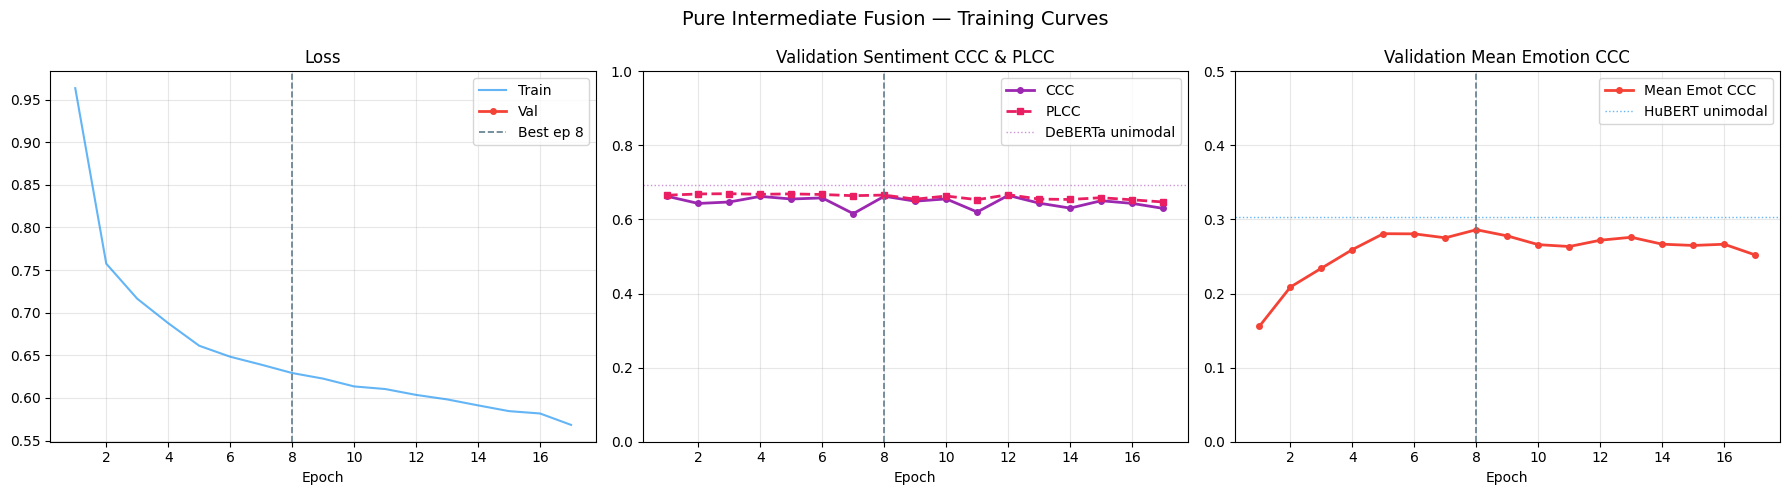

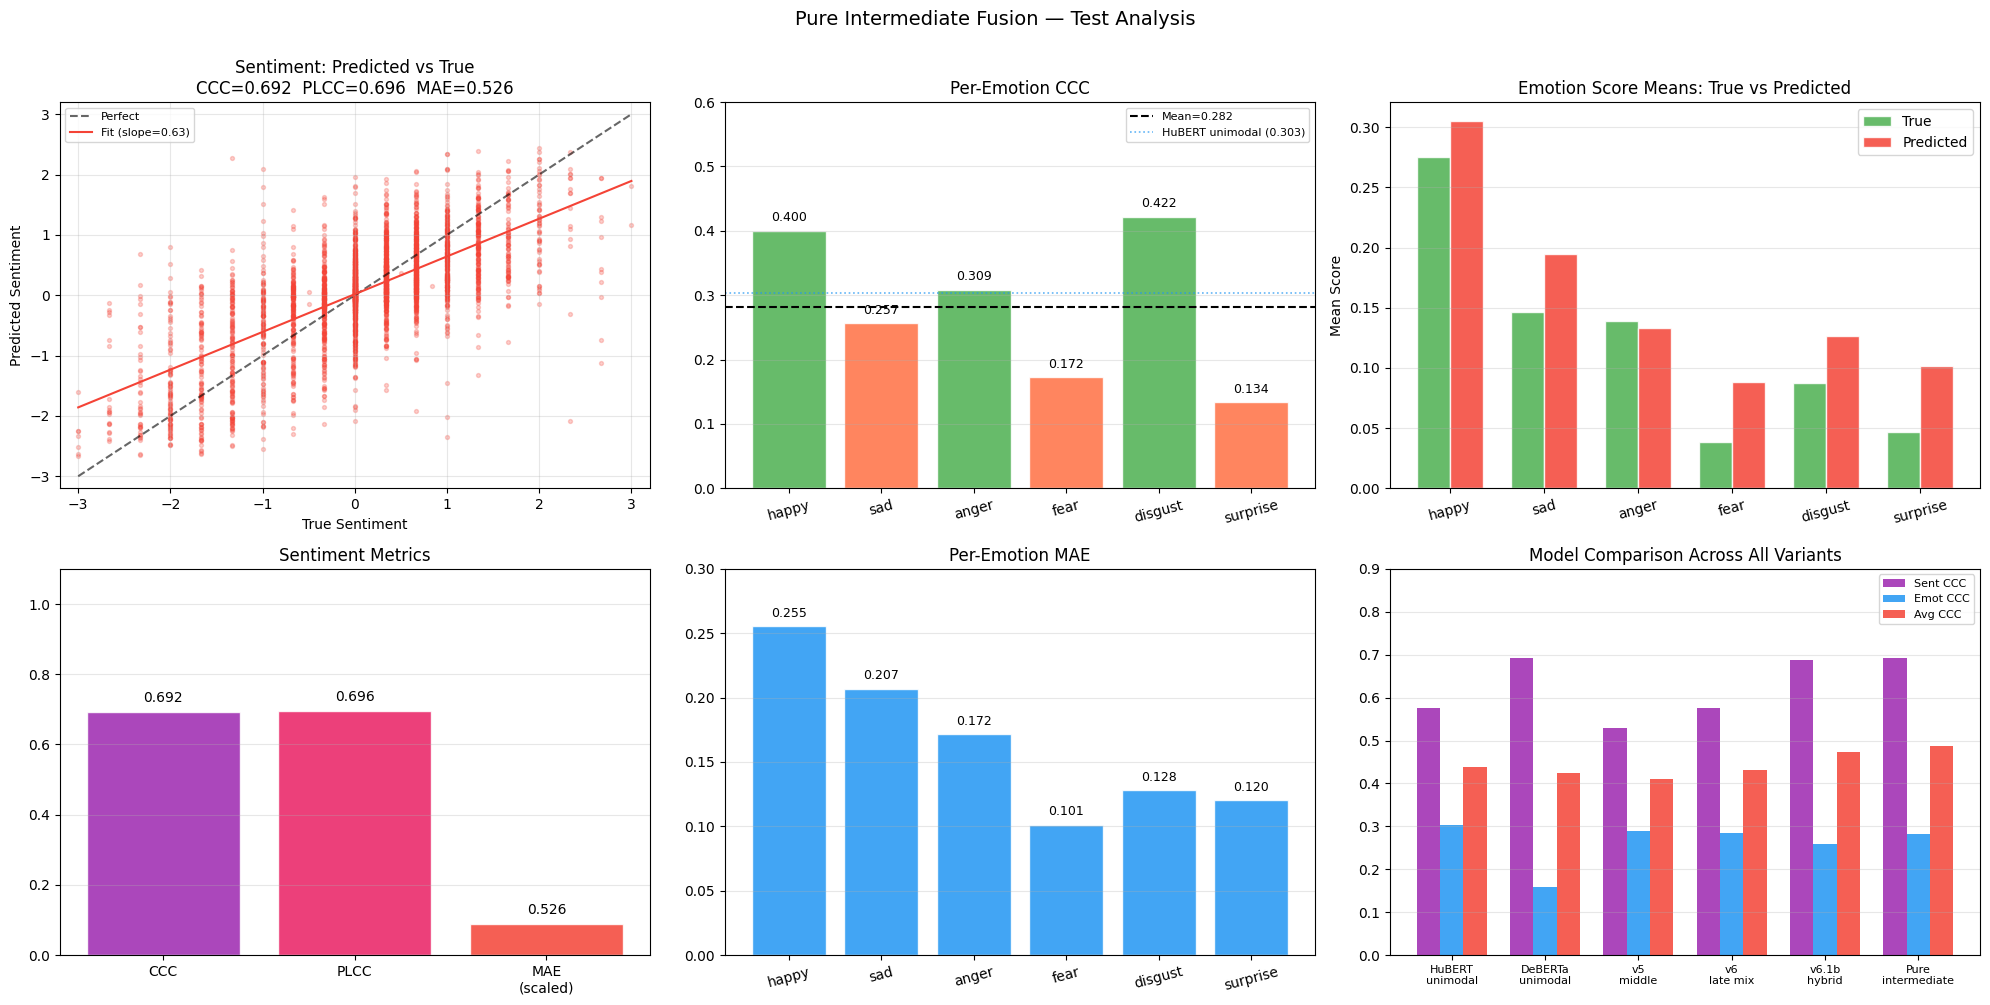


Figures saved to /content/drive/Shareddrives/AI Capstone/Middle Fusion/fusion-mosei-v61-clean


In [ ]:
# Pure Intermediate Fusion - Test Visualisations
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

C = {"text":"#9C27B0","audio":"#2196F3","video":"#FF9800",
     "combined":"#F44336","train":"#2196F3","val":"#F44336","best":"#607D8B"}

# Training curves
epochs_ran = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Pure Intermediate Fusion — Training Curves", fontsize=14)

ax = axes[0]
ax.plot(epochs_ran, history["train_loss"], color=C["train"], linewidth=1.5, alpha=0.7, label="Train")
val_loss_plot = [v if np.isfinite(v) else np.nan for v in history["val_loss"]]
ax.plot(epochs_ran, val_loss_plot, color=C["val"], linewidth=2, marker="o", markersize=4, label="Val")
ax.axvline(ckpt['best_epoch'], color=C["best"], linestyle="--", linewidth=1.2,
            label=f"Best ep {ckpt['best_epoch']}")
ax.set_title("Loss"); ax.set_xlabel("Epoch"); ax.legend(); ax.grid(True, alpha=0.3)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

ax = axes[1]
ax.plot(epochs_ran, history["sent_ccc"],  color=C["text"], linewidth=2, marker="o", markersize=4, label="CCC")
ax.plot(epochs_ran, history["sent_plcc"], color="#E91E63", linewidth=2, marker="s", markersize=4, linestyle="--", label="PLCC")
ax.axhline(0.6918, color=C["text"], linestyle=":", linewidth=1, alpha=0.5, label="DeBERTa unimodal")
ax.axvline(ckpt['best_epoch'], color=C["best"], linestyle="--", linewidth=1.2)
ax.set_title("Validation Sentiment CCC & PLCC"); ax.set_xlabel("Epoch"); ax.set_ylim(0, 1)
ax.legend(); ax.grid(True, alpha=0.3); ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

ax = axes[2]
ax.plot(epochs_ran, history["mean_emot_ccc"], color=C["combined"], linewidth=2, marker="o", markersize=4, label="Mean Emot CCC")
ax.axhline(0.3027, color=C["audio"], linestyle=":", linewidth=1, alpha=0.7, label="HuBERT unimodal")
ax.axvline(ckpt['best_epoch'], color=C["best"], linestyle="--", linewidth=1.2)
ax.set_title("Validation Mean Emotion CCC"); ax.set_xlabel("Epoch"); ax.set_ylim(0, 0.5)
ax.legend(); ax.grid(True, alpha=0.3); ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/intermediate_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# Test analysis (scatter + per-emotion + comparison)
sent_true  = np.array(test['sent_true'])
sent_preds = np.array(test['sent_pred'])
emot_true  = test['emot_true']
emot_preds = test['emot_pred']

fig2 = plt.figure(figsize=(20, 10))
fig2.suptitle("Pure Intermediate Fusion — Test Analysis", fontsize=14, y=1.00)

# Sentiment scatter
ax = fig2.add_subplot(2, 3, 1)
ax.scatter(sent_true, sent_preds, alpha=0.25, s=8, color=C["combined"], rasterized=True)
ax.plot([-3, 3], [-3, 3], "k--", linewidth=1.5, alpha=0.6, label="Perfect")
m, b = np.polyfit(sent_true, sent_preds, 1)
ax.plot([-3, 3], [m*-3+b, m*3+b], color=C["combined"], linewidth=1.5, label=f"Fit (slope={m:.2f})")
ax.set_title(f"Sentiment: Predicted vs True\nCCC={test['sent_ccc']:.3f}  PLCC={test['sent_plcc']:.3f}  MAE={test['sent_mae']:.3f}")
ax.set_xlabel("True Sentiment"); ax.set_ylabel("Predicted Sentiment")
ax.set_xlim(-3.2, 3.2); ax.set_ylim(-3.2, 3.2)
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# Per-emotion CCC
ax = fig2.add_subplot(2, 3, 2)
bar_colors = ["#4CAF50" if c >= test["mean_emot_ccc"] else "#FF7043"
              for c in test["emot_ccc_scores"]]
bars = ax.bar(EMOTION_COLS, test["emot_ccc_scores"], color=bar_colors, alpha=0.85, edgecolor="white")
ax.axhline(test["mean_emot_ccc"], color="black", linestyle="--", linewidth=1.5, label=f"Mean={test['mean_emot_ccc']:.3f}")
ax.axhline(0.3027, color=C["audio"], linestyle=":", linewidth=1.2, alpha=0.7, label="HuBERT unimodal (0.303)")
for bar, val in zip(bars, test["emot_ccc_scores"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{val:.3f}", ha="center", va="bottom", fontsize=9)
ax.set_title("Per-Emotion CCC"); ax.set_ylim(0, 0.6); ax.tick_params(axis="x", rotation=15)
ax.legend(fontsize=8); ax.grid(True, alpha=0.3, axis="y")

# True vs predicted emotion means
ax = fig2.add_subplot(2, 3, 3)
x = np.arange(len(EMOTION_COLS)); w = 0.35
ax.bar(x - w/2, emot_true.mean(axis=0), w, label="True", color="#4CAF50", alpha=0.85, edgecolor="white")
ax.bar(x + w/2, emot_preds.mean(axis=0), w, label="Predicted", color=C["combined"], alpha=0.85, edgecolor="white")
ax.set_xticks(x); ax.set_xticklabels(EMOTION_COLS, rotation=15)
ax.set_title("Emotion Score Means: True vs Predicted"); ax.set_ylabel("Mean Score")
ax.legend(); ax.grid(True, alpha=0.3, axis="y")

# Sentiment metric summary
ax = fig2.add_subplot(2, 3, 4)
metrics = ['CCC', 'PLCC', 'MAE\n(scaled)']
values = [test['sent_ccc'], test['sent_plcc'], test['sent_mae'] / 6.0]  # scale MAE to 0-1
true_vals = [1.0, 1.0, 0.0]
bars = ax.bar(metrics, values, color=[C["text"], "#E91E63", C["combined"]], alpha=0.85, edgecolor="white")
for bar, val, raw in zip(bars, values, [test['sent_ccc'], test['sent_plcc'], test['sent_mae']]):
    label = f"{raw:.3f}"
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            label, ha="center", va="bottom", fontsize=10)
ax.set_title("Sentiment Metrics"); ax.set_ylim(0, 1.1)
ax.grid(True, alpha=0.3, axis="y")

# Per-emotion MAE
ax = fig2.add_subplot(2, 3, 5)
emot_mae_per = [mean_absolute_error(emot_true[:, i], emot_preds[:, i]) for i in range(6)]
bars = ax.bar(EMOTION_COLS, emot_mae_per, color=C["audio"], alpha=0.85, edgecolor="white")
for bar, val in zip(bars, emot_mae_per):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f"{val:.3f}", ha="center", va="bottom", fontsize=9)
ax.set_title("Per-Emotion MAE"); ax.tick_params(axis="x", rotation=15)
ax.set_ylim(0, 0.3); ax.grid(True, alpha=0.3, axis="y")

# Model comparison (now showing intermediate as winner)
ax = fig2.add_subplot(2, 3, 6)
models = ["HuBERT\nunimodal", "DeBERTa\nunimodal", "v5\nmiddle", "v6\nlate mix",
          "v6.1b\nhybrid", "Pure\nintermediate"]
sccc_v = [0.5756, 0.6918, 0.5302, 0.5762, 0.6869, test["sent_ccc"]]
eccc_v = [0.3027, 0.1587, 0.2900, 0.2851, 0.2599, test["mean_emot_ccc"]]
avg_v  = [(s + e) / 2 for s, e in zip(sccc_v, eccc_v)]
x6 = np.arange(len(models)); w6 = 0.25
ax.bar(x6 - w6, sccc_v, w6, label="Sent CCC", color="#9C27B0", alpha=0.85)
ax.bar(x6,      eccc_v, w6, label="Emot CCC", color=C["audio"], alpha=0.85)
ax.bar(x6 + w6, avg_v,  w6, label="Avg CCC",  color=C["combined"], alpha=0.85)
ax.set_xticks(x6); ax.set_xticklabels(models, fontsize=8)
ax.set_title("Model Comparison Across All Variants"); ax.set_ylim(0, 0.9)
ax.legend(fontsize=8); ax.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/intermediate_test_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nFigures saved to {OUTPUT_DIR}")

In [ ]:
import json
with open(f"{OUTPUT_DIR}/intermediate_test_results.json", 'w') as f:
    json.dump({
        "sent_ccc": test['sent_ccc'], "sent_plcc": test['sent_plcc'], "sent_mae": test['sent_mae'],
        "mean_emot_ccc": test['mean_emot_ccc'], "emot_mae": test['emot_mae'],
        "emot_ccc_scores": test['emot_ccc_scores'],
        "avg_ccc": (test['sent_ccc']+test['mean_emot_ccc'])/2,
        "best_epoch": int(ckpt['best_epoch']),
        "best_val_avg_ccc": float(ckpt['best_avg_ccc']),
    }, f, indent=2)
print("Saved")

Saved


In [ ]:
import os
files_to_check = [
    f"{OUTPUT_DIR}/resume_checkpoint_intermediate.pt",
    f"{OUTPUT_DIR}/intermediate_training_curves.png",
    f"{OUTPUT_DIR}/intermediate_test_analysis.png",
]
for f in files_to_check:
    exists = os.path.exists(f)
    size = os.path.getsize(f) / 1e6 if exists else 0
    print(f"  {'✓' if exists else '✗'} {os.path.basename(f)}: {size:.1f} MB" if exists else f"  ✗ MISSING: {os.path.basename(f)}")

  ✓ resume_checkpoint_intermediate.pt: 527.2 MB
  ✓ intermediate_training_curves.png: 0.1 MB
  ✓ intermediate_test_analysis.png: 0.3 MB
